In [1]:
import pandas as pd
import numpy as np

# Standard column names for the 14-column Housing dataset
column_names = [
    'CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 
    'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV'
]

# Load whitespace-delimited dataset
df_house = pd.read_csv('4) house Prediction Data Set.csv', sep=r'\s+', header=None, names=column_names)

print(f"Dataset Shape: {df_house.shape}")
print("\n--- Missing Values Audit ---")
print(df_house.isnull().sum().sum(), "total missing values")

print("\n--- First 5 Rows ---")
display(df_house.head())

print("\n--- Target Variable (MEDV) Summary ---")
print(df_house['MEDV'].describe())

Dataset Shape: (506, 14)

--- Missing Values Audit ---
0 total missing values

--- First 5 Rows ---


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2



--- Target Variable (MEDV) Summary ---
count    506.000000
mean      22.532806
std        9.197104
min        5.000000
25%       17.025000
50%       21.200000
75%       25.000000
max       50.000000
Name: MEDV, dtype: float64


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Separate predictors and target
X = df_house.drop(columns=['MEDV'])
y = df_house['MEDV']

# 1. 80/20 Train/Test Split BEFORE scaling to prevent leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# 2. Fit StandardScaler strictly on X_train
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Train Baseline Linear Regression Model
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

# 4. Predict and Evaluate on Test Set
y_pred_lr = lr_model.predict(X_test_scaled)

mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("--- Baseline Linear Regression Performance (Test Set) ---")
print(f"MSE  : {mse_lr:.4f}")
print(f"RMSE : {rmse_lr:.4f} ($k)")
print(f"MAE  : {mae_lr:.4f} ($k)")
print(f"R²   : {r2_lr:.4f}")

--- Baseline Linear Regression Performance (Test Set) ---
MSE  : 24.2911
RMSE : 4.9286 ($k)
MAE  : 3.1891 ($k)
R²   : 0.6688


--- Regression Model Comparison (Test Set) ---


,Model,MSE,RMSE ($k),MAE ($k),R² Score
0,Linear Regression,24.2911,4.9286,3.1891,0.6688
1,Decision Tree Regressor,17.8156,4.2209,2.7245,0.7571
2,Random Forest Regressor,7.8802,2.8072,2.0367,0.8925


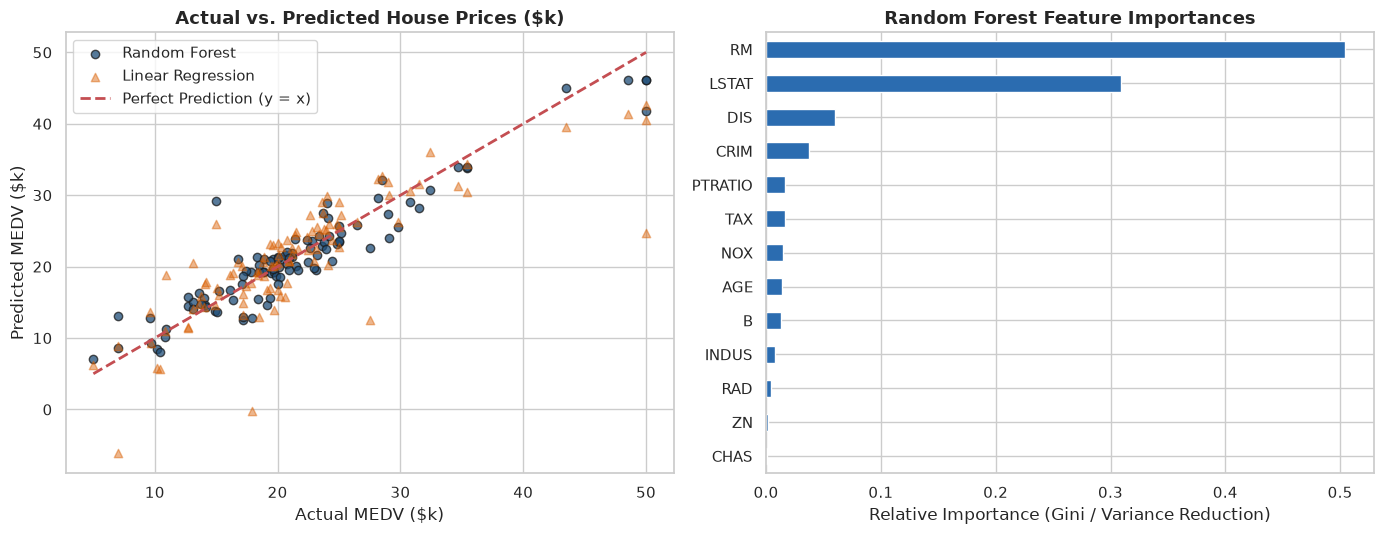

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# 1. Train Decision Tree Regressor
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

# 2. Train Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

# 3. Compile Model Comparison Table
results = []
for name, preds in [
    ("Linear Regression", y_pred_lr),
    ("Decision Tree Regressor", y_pred_dt),
    ("Random Forest Regressor", y_pred_rf)
]:
    mse = mean_squared_error(y_test, preds)
    results.append({
        "Model": name,
        "MSE": round(mse, 4),
        "RMSE ($k)": round(np.sqrt(mse), 4),
        "MAE ($k)": round(mean_absolute_error(y_test, preds), 4),
        "R² Score": round(r2_score(y_test, preds), 4)
    })

df_results = pd.DataFrame(results)
print("--- Regression Model Comparison (Test Set) ---")
display(df_results)

# 4. Two-Panel Diagnostic Visualization
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left Panel: Actual vs Predicted (Random Forest vs Linear Regression)
axes[0].scatter(y_test, y_pred_rf, alpha=0.75, color="#1f4e78", edgecolor="k", label="Random Forest")
axes[0].scatter(y_test, y_pred_lr, alpha=0.45, color="#d95f02", marker="^", label="Linear Regression")
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2, label="Perfect Prediction (y = x)")
axes[0].set_title("Actual vs. Predicted House Prices ($k)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Actual MEDV ($k)")
axes[0].set_ylabel("Predicted MEDV ($k)")
axes[0].legend()

# Right Panel: Random Forest Feature Importances
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=True)
importances.plot(kind="barh", ax=axes[1], color="#2b6cb0")
axes[1].set_title("Random Forest Feature Importances", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Relative Importance (Gini / Variance Reduction)")

plt.tight_layout()
plt.show()